In [11]:
from ultralytics import YOLO 
import cv2 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import math

In [12]:
model = YOLO('/Users/keagon_beatty/Documents/Machine_Learning/coil_project/runs/obb/train7/weights/best.pt')

In [13]:
# Load the image
image_path = "/Users/keagon_beatty/Documents/Machine_Learning/coil_project/1/rendered_image_91_90_1.png"  # Replace with your image path
image = Image.open(image_path)

# Perform predictions
results = model.predict(image_path, conf=0.5)  # Adjust confidence threshold if needed

# Extract predictions
raw_predictions = results[0].obb.xywhr  # Assuming batch size of 1

#print(raw_predictions)
predictions = []
for tens in raw_predictions:
    predictions.append(tens.tolist())

for prediction in predictions:
    print(prediction)


image 1/1 /Users/keagon_beatty/Documents/Machine_Learning/coil_project/1/rendered_image_91_90_1.png: 768x1024 46.8ms
Speed: 1.4ms preprocess, 46.8ms inference, 0.5ms postprocess per image at shape (1, 3, 768, 1024)
[495.3169860839844, 492.195068359375, 157.7550811767578, 67.80784606933594, 1.5893303155899048]
[495.26190185546875, 303.2787780761719, 154.3321533203125, 66.06024169921875, 1.592868685722351]
[398.326416015625, 255.88804626464844, 159.7672119140625, 68.55731201171875, 1.5888385772705078]
[301.70819091796875, 305.61572265625, 157.42706298828125, 66.79994201660156, 1.5897037982940674]
[398.1734619140625, 445.8519287109375, 158.35952758789062, 67.98883056640625, 1.5876020193099976]
[592.364013671875, 255.2528533935547, 158.98411560058594, 68.84803009033203, 1.5951998233795166]
[302.07330322265625, 493.917724609375, 158.89529418945312, 67.35121154785156, 1.5888864994049072]
[592.3439331054688, 446.0604553222656, 156.34341430664062, 68.6483154296875, 1.592682957649231]
[689.321

In [14]:
print(results[0].obb.xywhr)

tensor([[495.3170, 492.1951, 157.7551,  67.8078,   1.5893],
        [495.2619, 303.2788, 154.3322,  66.0602,   1.5929],
        [398.3264, 255.8880, 159.7672,  68.5573,   1.5888],
        [301.7082, 305.6157, 157.4271,  66.7999,   1.5897],
        [398.1735, 445.8519, 158.3595,  67.9888,   1.5876],
        [592.3640, 255.2529, 158.9841,  68.8480,   1.5952],
        [302.0733, 493.9177, 158.8953,  67.3512,   1.5889],
        [592.3439, 446.0605, 156.3434,  68.6483,   1.5927],
        [689.3210, 303.4548, 159.5809,  68.6360,   1.5820],
        [689.2531, 493.1998, 158.5062,  68.8899,   1.5809]])


/var/folders/4p/00p49d_90_3dmt536pgzqb9w0000gn/T/ipykernel_4902/1543791066.py:17: DeprecationWarning: `np.int0` is a deprecated alias for `np.intp`.  (Deprecated NumPy 1.24)
  box_points = np.int0(box_points)  # Convert to integer coordinates


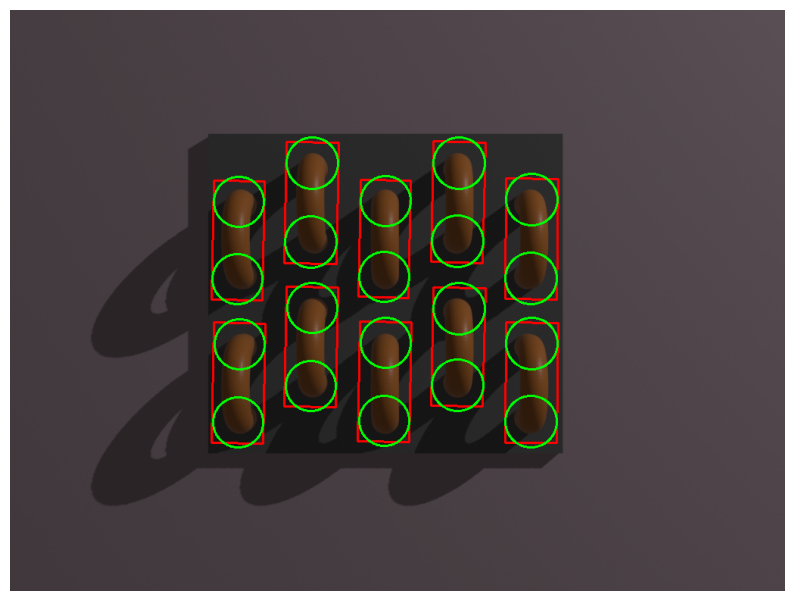

In [15]:
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB for display

circles = []
# Iterate over predictions and draw rotated rectangles and circles
for i in range(0, len(predictions)):
#for pred in predictions:
    pred = predictions[i]
    x_center, y_center, width, height, angle = pred
    angle_degrees = angle * 180 / np.pi  # Convert radians to degrees for OpenCV

    # Define the rotated rectangle
    rect = ((x_center, y_center), (width, height), angle_degrees)

    # Get the four corner points of the rotated rectangle
    box_points = cv2.boxPoints(rect)
    box_points = np.int0(box_points)  # Convert to integer coordinates

    # Draw the rotated rectangle
    cv2.polylines(image, [box_points], isClosed=True, color=(255, 0, 0), thickness=2)

    # Draw a circle at the center of the bounding box
    circ_x =(np.cos(pred[4]) * ((width * .65) / 2))
    circ_y =(np.sin(pred[4]) * ((width * .65) / 2))
    radius = int(height / 2)
    add_circles1 = [int(x_center + circ_x), int(y_center + circ_y), radius, i]
    add_circles2 = [int(x_center - circ_x), int(y_center - circ_y), radius, i]
    cv2.circle(image, (int(x_center + circ_x), int(y_center + circ_y)), radius, (0, 255, 0), thickness=2)
    cv2.circle(image, (int(x_center - circ_x), int(y_center - circ_y)), radius, (0, 255, 0), thickness=2)
    circles.append(add_circles1)
    circles.append(add_circles2)

# Display the image with bounding boxes and circles
plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.axis("off")
plt.show()


In [16]:
coordinates = pd.DataFrame(circles, columns=['X', 'Y', 'Radius', 'return_bend'])

In [17]:
divisions = (coordinates['X'].max() - coordinates['X'].min())/5

In [18]:
print(coordinates.sort_values(by='X'))

      X    Y  Radius  return_bend
6   300  356      33            3
12  301  545      33            6
7   302  254      33            3
13  303  442      33            6
8   397  497      33            4
4   397  307      34            2
9   399  394      33            4
5   399  203      34            2
0   494  543      33            0
2   494  353      33            1
1   496  440      33            0
3   496  253      33            1
10  591  306      34            5
14  591  496      34            7
11  593  203      34            5
15  593  395      34            7
18  688  544      34            9
16  688  355      34            8
17  689  251      34            8
19  689  441      34            9


length of circles array: 20


/var/folders/4p/00p49d_90_3dmt536pgzqb9w0000gn/T/ipykernel_4902/2705176325.py:22: DeprecationWarning: `np.int0` is a deprecated alias for `np.intp`.  (Deprecated NumPy 1.24)
  box_points = np.int0(box_points)  # Convert to integer coordinates


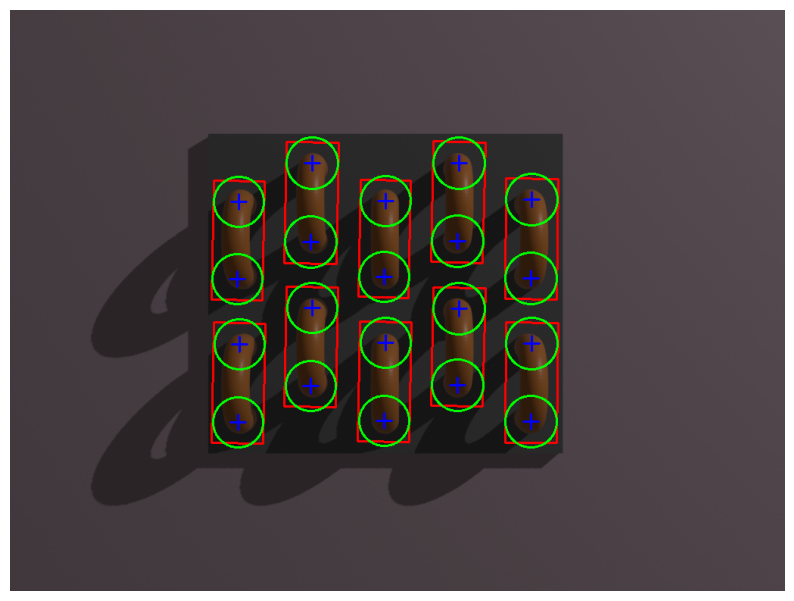

In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Load the image
image = cv2.imread(image_path)
if image is None:
    raise ValueError("Image not loaded. Check the image path.")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB for display

# Iterate over predictions and draw rotated rectangles and circles
for pred in predictions:
    x_center, y_center, width, height, angle = pred
    angle_degrees = angle * 180 / np.pi  # Convert radians to degrees for OpenCV

    # Define the rotated rectangle
    rect = ((x_center, y_center), (width, height), angle_degrees)

    # Get the four corner points of the rotated rectangle
    box_points = cv2.boxPoints(rect)
    box_points = np.int0(box_points)  # Convert to integer coordinates

    # Draw the rotated rectangle
    cv2.polylines(image, [box_points], isClosed=True, color=(255, 0, 0), thickness=2)

    # Draw a circle at the center of the bounding box
    circ_x =(np.cos(pred[4]) * ((width * .65) / 2))
    circ_y =(np.sin(pred[4]) * ((width * .65) / 2))
    radius = int(height / 2)
    cv2.circle(image, (int(x_center + circ_x), int(y_center + circ_y)), radius, (0, 255, 0), thickness=2)
    cv2.circle(image, (int(x_center - circ_x), int(y_center - circ_y)), radius, (0, 255, 0), thickness=2)

    # Add horizontal lines

for circle in circles:
    cv2.line(image, (circle[0], circle[1]-10), (circle[0], circle[1]+10), color=(0, 0, 255), thickness = 2)
    cv2.line(image, (circle[0]-10, circle[1]), (circle[0]+10, circle[1]), color=(0, 0, 255), thickness = 2)
# Display the image with bounding boxes, circles, and horizontal lines

print(f'length of circles array: {len(circles)}')
plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.axis("off")
plt.show()

In [20]:
x_rows = 5

x_groups = (coordinates['X'].max() - coordinates['X'].min()) / (x_rows-1)
x_inter_group_space = x_groups * .25

print(x_groups)

y_rows = 8
y_groups = (coordinates['Y'].max() - coordinates['Y'].min()) / (y_rows - 1)
y_inter_group_space = y_groups * .25

print(y_groups)

97.25
48.857142857142854


/var/folders/4p/00p49d_90_3dmt536pgzqb9w0000gn/T/ipykernel_4902/1737663569.py:22: DeprecationWarning: `np.int0` is a deprecated alias for `np.intp`.  (Deprecated NumPy 1.24)
  box_points = np.int0(box_points)  # Convert to integer coordinates


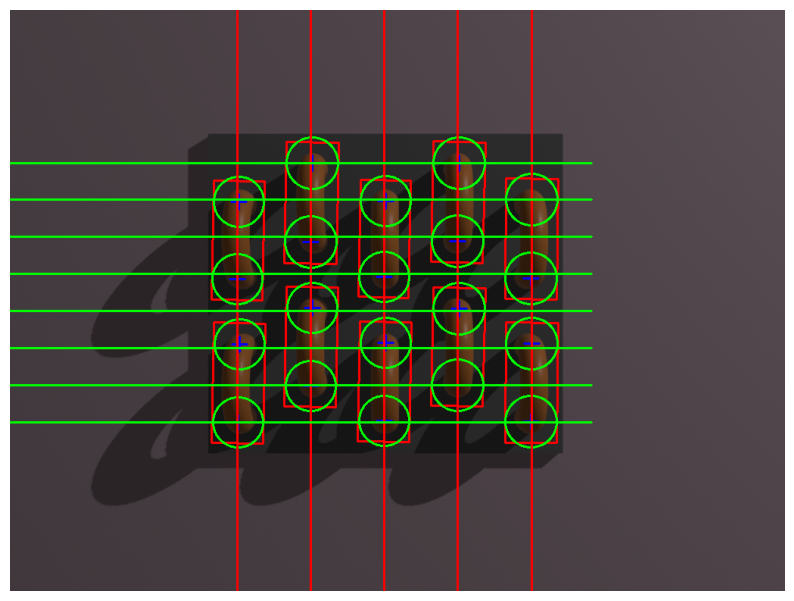

In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Load the image
image = cv2.imread(image_path)
if image is None:
    raise ValueError("Image not loaded. Check the image path.")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB for display

# Iterate over predictions and draw rotated rectangles and circles
for pred in predictions:
    x_center, y_center, width, height, angle = pred
    angle_degrees = angle * 180 / np.pi  # Convert radians to degrees for OpenCV

    # Define the rotated rectangle
    rect = ((x_center, y_center), (width, height), angle_degrees)

    # Get the four corner points of the rotated rectangle
    box_points = cv2.boxPoints(rect)
    box_points = np.int0(box_points)  # Convert to integer coordinates

    # Draw the rotated rectangle
    cv2.polylines(image, [box_points], isClosed=True, color=(255, 0, 0), thickness=2)

    # Draw a circle at the center of the bounding box
    circ_x = (np.cos(pred[4]) * ((width * .65) / 2))
    circ_y = (np.sin(pred[4]) * ((width * .65) / 2))
    radius = int(height / 2)
    cv2.circle(image, (int(x_center + circ_x), int(y_center + circ_y)), radius, (0, 255, 0), thickness=2)
    cv2.circle(image, (int(x_center - circ_x), int(y_center - circ_y)), radius, (0, 255, 0), thickness=2)


# Add horizontal lines
for circle in circles:
    cv2.line(image, (circle[0], circle[1] - 10), (circle[0], circle[1] + 10), color=(0, 0, 255), thickness=2)
    cv2.line(image, (circle[0] - 10, circle[1]), (circle[0] + 10, circle[1]), color=(0, 0, 255), thickness=2)

for i in range(0, x_rows):
    y_coord = int(coordinates['X'].min() + (x_groups * i))  # Ensure y_coord is an integer
    cv2.line(image, (y_coord, 0), (y_coord, image.shape[1]), color=(255, 0, 0), thickness=2)

for i in range(0, y_rows):
    x_coord = int(coordinates['Y'].min() + (y_groups * i))
    cv2.line(image, (0, x_coord), (image.shape[0], x_coord), color=(0, 255, 0), thickness=2)


# Display the image with bounding boxes, circles, and horizontal lines
plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.axis("off")
plt.show()


In [22]:

x_group_list=[]
for i in range(0, x_rows):
    y_coord = int(coordinates['X'].min() + (x_groups * i))
    x_group_list.append((y_coord - x_inter_group_space, y_coord + x_inter_group_space))

y_group_list=[]
for i in range(0, y_rows):
    x_coord = int(coordinates['Y'].min() + (y_groups * i))
    y_group_list.append((x_coord - y_inter_group_space, x_coord + y_inter_group_space))

print(x_group_list)
print(y_group_list)
    

[(275.6875, 324.3125), (372.6875, 421.3125), (469.6875, 518.3125), (566.6875, 615.3125), (664.6875, 713.3125)]
[(190.78571428571428, 215.21428571428572), (238.78571428571428, 263.2142857142857), (287.7857142857143, 312.2142857142857), (336.7857142857143, 361.2142857142857), (385.7857142857143, 410.2142857142857), (434.7857142857143, 459.2142857142857), (483.7857142857143, 508.2142857142857), (532.7857142857143, 557.2142857142857)]


In [23]:

# Function to assign groups based on predefined ranges
def assign_group_x(x):
    for i, (min_val, max_val) in enumerate(x_group_list):
        if min_val <= x < max_val:
            return i
    return len(x_group_list)  # Default if value doesn't fit any range

def assign_group_y(y):
    for i, (min_val, max_val) in enumerate(y_group_list):
        if min_val <= y < max_val:
            return i
    return len(y_group_list)  # Default if value doesn't fit any range


In [24]:
# Apply the function to the 'X' column
coordinates['Group_X'] = coordinates['X'].apply(assign_group_x)
coordinates['Group_Y'] = coordinates['Y'].apply(assign_group_y)

print(coordinates)

      X    Y  Radius  return_bend  Group_X  Group_Y
0   494  543      33            0        2        7
1   496  440      33            0        2        5
2   494  353      33            1        2        3
3   496  253      33            1        2        1
4   397  307      34            2        1        2
5   399  203      34            2        1        0
6   300  356      33            3        0        3
7   302  254      33            3        0        1
8   397  497      33            4        1        6
9   399  394      33            4        1        4
10  591  306      34            5        3        2
11  593  203      34            5        3        0
12  301  545      33            6        0        7
13  303  442      33            6        0        5
14  591  496      34            7        3        6
15  593  395      34            7        3        4
16  688  355      34            8        4        3
17  689  251      34            8        4        1
18  688  544

In [25]:
print(coordinates.sort_values(by='return_bend'))

      X    Y  Radius  return_bend  Group_X  Group_Y
0   494  543      33            0        2        7
1   496  440      33            0        2        5
2   494  353      33            1        2        3
3   496  253      33            1        2        1
4   397  307      34            2        1        2
5   399  203      34            2        1        0
6   300  356      33            3        0        3
7   302  254      33            3        0        1
9   399  394      33            4        1        4
8   397  497      33            4        1        6
10  591  306      34            5        3        2
11  593  203      34            5        3        0
12  301  545      33            6        0        7
13  303  442      33            6        0        5
14  591  496      34            7        3        6
15  593  395      34            7        3        4
16  688  355      34            8        4        3
17  689  251      34            8        4        1
18  688  544

In [26]:
# Your DataFrame
data = coordinates

df = pd.DataFrame(data)

# Group by 'return_bend'
grouped = df.groupby('return_bend')[['Group_X', 'Group_Y']]

# Format the grouped data into the desired string
result = '{' + ','.join(
    '{{{}}}'.format(
        ','.join('{{{},{}}}'.format(row['Group_X'], row['Group_Y']) for _, row in group.iterrows())
    )
    for _, group in grouped
) + '}'

print(result)


{{{2,7},{2,5}},{{2,3},{2,1}},{{1,2},{1,0}},{{0,3},{0,1}},{{1,6},{1,4}},{{3,2},{3,0}},{{0,7},{0,5}},{{3,6},{3,4}},{{4,3},{4,1}},{{4,7},{4,5}}}
